
# Tidy Data Project

### Project Overview

The goal of this project is to clean/ reorganzie data from the 2008 Olympics using Python and Pandas. The original dataset contains medalists names and seperate columns for difference sports and genders. By applying tidy data principles, I restructed the dataset to make it easier to analyze by sport type, medal types and genders.

Pivot tables and visulatzations are used to explore patterns in the cleaned data

### Original Dataset

The original dataset contains 1,875 rows and 71 columns with each athlete having their own row. Each column is a seperate gender and sport, and the values list which athlete won a medal (and the medal type) for the various sports.

The format makes it confusing to comapre medal enteries between sports and genders because these variables are combined into many columns. The data set is reorganized so that each variable has its own column.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# load dataset
df_olympics = pd.read_csv('olympics_08_medalists.csv')

print("Original Olympic Medalists DataFrame:")
print(df_olympics)

print(df_olympics.columns.tolist())

Original Olympic Medalists DataFrame:
          medalist_name male_archery female_archery male_athletics  \
0       Aaron Armstrong          NaN            NaN           gold   
1         Aaron Peirsol          NaN            NaN            NaN   
2      Abdullo Tangriev          NaN            NaN            NaN   
3     Abeer Abdelrahman          NaN            NaN            NaN   
4               Abhinav          NaN            NaN            NaN   
...                 ...          ...            ...            ...   
1870        Éver Banega          NaN            NaN            NaN   
1871  Ólafur Stefánsson          NaN            NaN            NaN   
1872      Óscar Brayson          NaN            NaN            NaN   
1873   Łukasz Pawłowski          NaN            NaN            NaN   
1874        Živko Gocić          NaN            NaN            NaN   

     female_athletics male_badminton female_badminton male_baseball  \
0                 NaN            NaN              

### Melting the Data

pd.melt() is used to convert the dataset from a wide format to a long format. The medalist_name column was held constant while the original sport and gender columns were combined into a new column called Gender_Sport. The observations in these columns were placed into a different column named medal (as the values in these orginial colmuns held the medal type of the atheltes in these various sports)

This made it easier to work wiht the different medal enteries without having to analyze each gender/sport column individually

In [2]:
# melt data frame: convert from wide to long
df_olypmics_melted = pd.melt(
    df_olympics,
    id_vars = ['medalist_name'],
    var_name = 'Gender_Sport',
    value_name = 'Medal'
)

print("Melted Olympic Medalists DataFrame:")
print(df_olypmics_melted.head(10))


Melted Olympic Medalists DataFrame:
       medalist_name  Gender_Sport Medal
0    Aaron Armstrong  male_archery   NaN
1      Aaron Peirsol  male_archery   NaN
2   Abdullo Tangriev  male_archery   NaN
3  Abeer Abdelrahman  male_archery   NaN
4            Abhinav  male_archery   NaN
5    Acer Nethercott  male_archery   NaN
6         Adam Korol  male_archery   NaN
7         Adam Kreek  male_archery   NaN
8          Adam Pine  male_archery   NaN
9       Adam Wheeler  male_archery   NaN


### Removing Missing Values

After melting the data, many rows contained missing medal values because many athletes only earned a medal in certain sports.

.dropna() was used to remove rows that contained missing values in the medal column which allowed the cleaned dataset to only contain actual recorded medal enteries.

In [3]:
# remove rows w/ missing medal values
df_olympics_clean = df_olypmics_melted.dropna(subset=['Medal']).copy()

print("Olympics DataFrame Without Mising Values: ")
print(df_olympics_clean.head(15))

Olympics DataFrame Without Mising Values: 
        medalist_name    Gender_Sport   Medal
177      Bair Badënov    male_archery  bronze
676     Ilario Di Buò    male_archery  silver
682      Im Dong-hyun    male_archery    gold
760         Jiang Lin    male_archery  bronze
920    Lee Chang-hwan    male_archery    gold
950        Li Wenquan    male_archery  bronze
1043   Marco Galiazzo    male_archery  silver
1107    Mauro Nespoli    male_archery  silver
1314    Park Kyung-mo    male_archery  silver
1710     Viktor Ruban    male_archery    gold
1768      Xue Haifeng    male_archery  bronze
2124  Bérengère Schuh  female_archery  bronze
2160        Chen Ling  female_archery  silver
2472          Guo Dan  female_archery  silver
2656    Joo Hyun-Jung  female_archery    gold


### Seperating Gender and Sport

The Gender_Sport column still conatined two differencet variabels combined into one (gender and sport). .

.str.split('_') was used to seperates these variabels into their own columns: gender and sport.

In [4]:
# split Gender_Sport into two seperate columns

df_olympics_clean['Gender'] = df_olympics_clean['Gender_Sport'].str.split('_').str[0]
df_olympics_clean['Sport'] = df_olympics_clean['Gender_Sport'].str.split('_').str[1]

print("Olympics DataFrame with Gender and Sport:")
print(df_olympics_clean.head(15))

Olympics DataFrame with Gender and Sport:
        medalist_name    Gender_Sport   Medal  Gender    Sport
177      Bair Badënov    male_archery  bronze    male  archery
676     Ilario Di Buò    male_archery  silver    male  archery
682      Im Dong-hyun    male_archery    gold    male  archery
760         Jiang Lin    male_archery  bronze    male  archery
920    Lee Chang-hwan    male_archery    gold    male  archery
950        Li Wenquan    male_archery  bronze    male  archery
1043   Marco Galiazzo    male_archery  silver    male  archery
1107    Mauro Nespoli    male_archery  silver    male  archery
1314    Park Kyung-mo    male_archery  silver    male  archery
1710     Viktor Ruban    male_archery    gold    male  archery
1768      Xue Haifeng    male_archery  bronze    male  archery
2124  Bérengère Schuh  female_archery  bronze  female  archery
2160        Chen Ling  female_archery  silver  female  archery
2472          Guo Dan  female_archery  silver  female  archery
2656    Joo H

### Remove Columns

Now that gender and sport were stored in seperate columns, the original column containing both of theses vraibles in one (Gender_Sport) could be removed using .drop().

In [5]:
# remove Gender_Sport column
df_olympics_clean = df_olympics_clean.drop(columns=['Gender_Sport'])

print("Tidy Olympics DataFrame:")
print(df_olympics_clean.head(15))

Tidy Olympics DataFrame:
        medalist_name   Medal  Gender    Sport
177      Bair Badënov  bronze    male  archery
676     Ilario Di Buò  silver    male  archery
682      Im Dong-hyun    gold    male  archery
760         Jiang Lin  bronze    male  archery
920    Lee Chang-hwan    gold    male  archery
950        Li Wenquan  bronze    male  archery
1043   Marco Galiazzo  silver    male  archery
1107    Mauro Nespoli  silver    male  archery
1314    Park Kyung-mo  silver    male  archery
1710     Viktor Ruban    gold    male  archery
1768      Xue Haifeng  bronze    male  archery
2124  Bérengère Schuh  bronze  female  archery
2160        Chen Ling  silver  female  archery
2472          Guo Dan  silver  female  archery
2656    Joo Hyun-Jung    gold  female  archery


### Sort the Cleaned Data

.sort_values() was sued to but the dataset back into alphabetical order by medalist name.

In [6]:
# put back in alphebetical order
df_olympics_clean = df_olympics_clean.sort_values(by='medalist_name')

print(df_olympics_clean.head(15))

# Check for missing values after cleaning
print(df_olympics_clean.isna().sum())

             medalist_name   Medal  Gender                  Sport
3750       Aaron Armstrong    gold    male              athletics
90001        Aaron Peirsol    gold    male               swimming
69377     Abdullo Tangriev  silver    male                   judo
123753   Abeer Abdelrahman  bronze  female          weightlifting
84379              Abhinav    gold    male         shooting sport
76880      Acer Nethercott  silver    male                 rowing
76881           Adam Korol    gold    male                 rowing
76882           Adam Kreek    gold    male                 rowing
90008            Adam Pine  silver    male               swimming
129384        Adam Wheeler  bronze    male  greco-roman wrestling
45010       Adam Wiercioch  silver    male                fencing
118136         Adam Wright  silver    male             water polo
18762   Adam van Koeverden  silver    male  canoeing and kayaking
11263          Adiel Palma  silver    male               baseball
5639      

### Final Tidy Dataset

The dataset follows the three tidy data principles of Hadley Wickmam:

1. Each variable has its own column. The variables are medalist_name, medal, gender, and sport.
2. Each observation has its own row. Each row represnets one athlete's medal entry in a particular sport.
3. Each type of observational unit forms its own table. The athletes medal entries are organized into one table/

This method of organizing data makes it easier to compare medal entries using pivot tables and visualizations.



### Pivot Table 1: Medal Entries by Sport Type and Medal Type

To compare medal entries across different sports, a pivot table is created that separates gold, silver, and bronze medals into columns. Each row represents a sport, and the count function calculates how many medal enteries fall into each category. This makes it easy to compare the number of different medal types across the various sports.

In [7]:
# pivot table showing medal enteries by sport and medal types
pivot_olympics = pd.pivot_table(
    df_olympics_clean,
    values = 'medalist_name',
    index='Sport',
    columns= 'Medal',
    aggfunc= 'count',
    fill_value=0
)

print("Olympic Medal Enteries by Sport and Medal Type: ")
print(pivot_olympics)

# counts medal entries for each sport by medal type

Olympic Medal Enteries by Sport and Medal Type: 
Medal                  bronze  gold  silver
Sport                                      
archery                     8     5       7
artistic gymnastics        19    14      16
association football       36    37      36
athletics                  55    52      59
badminton                   7     7       8
baseball                   24    24      24
basketball                 24    23      24
beach volleyball            4     4       4
bmx                         2     2       2
boxing                     22    11      11
canoeing and kayaking      27    24      23
diving                     11     7      11
equestrian sport           14    11      13
fencing                    15    18      21
field hockey               33    33      32
freestyle wrestling        22    11      11
greco-roman wrestling      13     7       7
handball                   28    29      28
judo                       28    14      14
modern pentathlon          

### Visualization 1: Top 10 Olympic Sports by Medal Entries

To see which sports had the most medal entries, I used .value_counts() to count the entries for each sport. Then, I created a bar chart of the ten sports with the highest counts.

This visualization allows for a comparison of medal enteries across the most commonly won sports.

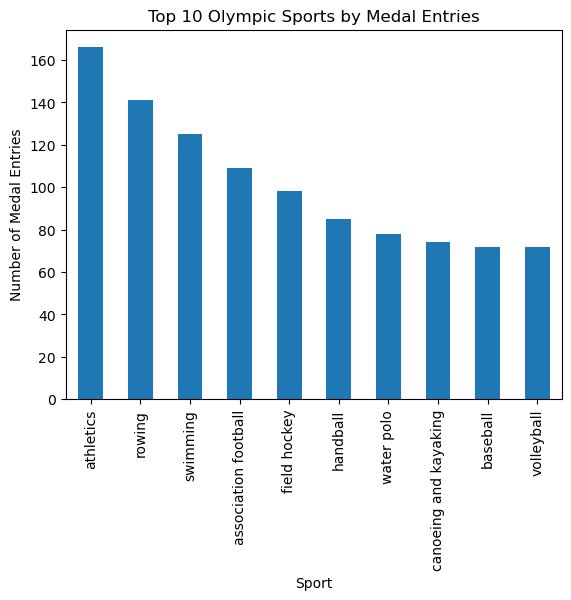

In [8]:
# count total number of medals for each sport
sport_counts = df_olympics_clean['Sport'].value_counts()
top_10_sports = sport_counts.head(10).index

# Bar chart of top 10 most successful sports
sport_counts.head(10).plot(kind='bar')

plt.title('Top 10 Olympic Sports by Medal Entries')
plt.xlabel('Sport')
plt.ylabel('Number of Medal Entries')
plt.show()

### Visual 1 Interpretations

Athletcis had the highest number of medal enteries in the dataset, followed closely by rowing and swimming. Tehse sports all include multiple events, which may contribute to explaining their higher medal counts. The graph also shows the variability of medal enteries across various Olympic sports.

### Visualization 2: Medal Types Across the Top 10 Sports

After identifyinf the ten sports with the highest number of medal enteries, I wanted to look more closely at how gold, silver, and bronze medals were distributed within these sports.

Using the first pivot table, I created a grouped bar chart to compare the three medal types within each sport.

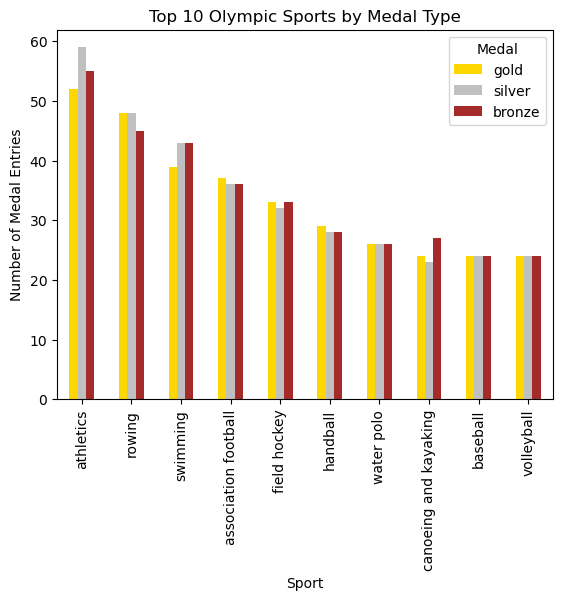

In [9]:
# Keep the top 10 sports
top_10_medals = pivot_olympics.reindex(top_10_sports)

# Put medal types in order
top_10_medals = top_10_medals[['gold', 'silver', 'bronze']]

# Bar chart
top_10_medals.plot(kind='bar', color=['gold', 'silver', 'brown'])

plt.title('Top 10 Olympic Sports by Medal Type')
plt.xlabel('Sport')
plt.ylabel('Number of Medal Entries')
plt.show()

### Visualization 2 Interpretations

Athletics had the highest number of enteries across all three medal types. For most sports, the number of gold, silver, and bronze entries were relatively similar, althought there were some slight differences. These differecnes could be explained by team sizes and the number of medal events that each sport has.

### Pivot Table 2: Medal Entries by Sport and Gender

Next, I wanted to compare the number of male and female entries across Olympic sports, so I created a second pivot table that seperates the entries by sport and gender.

In [10]:
# new pivot table for different analysis

# Pivot table comparing medal entries by sport and gender
pivot_gender = pd.pivot_table(
    df_olympics_clean,
    values='Medal',
    index= 'Sport',
    columns='Gender',
    aggfunc='count',
    fill_value=0
)

print("Olympic Medal Entries by Sport and Gender:")
print(pivot_gender)

Olympic Medal Entries by Sport and Gender:
Gender                 female  male
Sport                              
archery                     9    11
artistic gymnastics        20    29
association football       54    55
athletics                  81    85
badminton                  10    12
baseball                    0    72
basketball                 36    35
beach volleyball            6     6
bmx                         3     3
boxing                      0    44
canoeing and kayaking      21    53
diving                     13    16
equestrian sport           20    18
fencing                    26    28
field hockey               48    50
freestyle wrestling        16    28
greco-roman wrestling       0    27
handball                   42    43
judo                       28    28
modern pentathlon           2     3
mountain biking             3     3
rhythmic gymnastics        21     0
road bicycle racing         6     5
rowing                     58    83
sailing              

### Visualization 3: Medal Entries by Sport and Gender

For the visualization, I used the second pivot table to creaet a heatmap comparing male and female medal entries across the top ten sports. The reason a heatmap was selected for the visualization of this data is becasue the different shades of reds make it very easy to see which sports have higher or lower medal amounts for each gender.

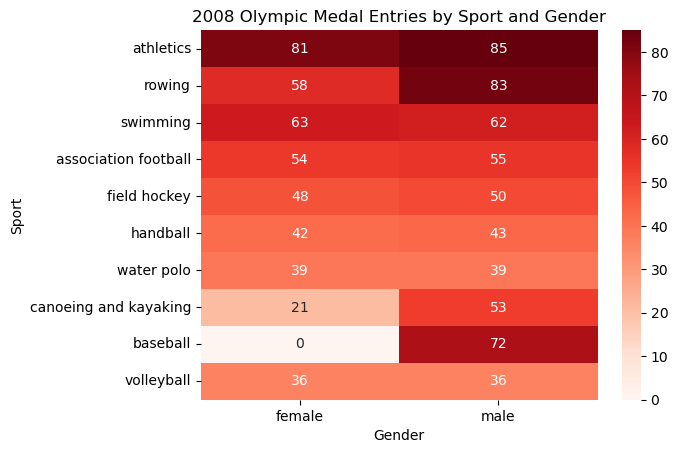

In [11]:
# heatmap

import seaborn as sns

# top 10 sports
top_10_gender = pivot_gender.reindex(top_10_sports)

# Create heatmap
sns.heatmap(top_10_gender, annot=True, cmap='Reds')

plt.title('2008 Olympic Medal Entries by Sport and Gender')
plt.xlabel('Gender')
plt.ylabel('Sport')
plt.show()

### Visualization 3 Interpretations

The heatmap shows differences in male and female medal entries across the top ten sports. Some sports had similar numbers of entries for both genders, such as athletics and association football; however, other sports had much larger differecnes. These differences could be related to the opportunities offered throughout the sports to the different genders, therefore, it is not fair to assume that the medal count differeces between genders is due to athletic performance alone.

### Conclusion

This project shows how tidy data principles can be used to reorganize a dataset so that it is easier to work with and analyze. By melting the original Olympic dataset, removing null values, and seperating gender and sport into their own columns, useful pivot tabels and visualizations were able to be created. These visualizations showed which sports had the highest number of medal enteries, and showed how medal enteries varied by gender across various sports.

However, this dataset records individual athlete medal entries which means that every member on a team sport was recorded to earn a medal. Thsi could potentially lead to a skewed medal count for team sports. A more useful dataset would include only the unique Olympic medals awarded.

### References
- Whickham, Hadly (2014) Tidy Data
- Comai, Giorgio 2008 Olympic Medalists Dataset